# Proyecto 2 · Detección de jugadores y separación de equipos
## Visión por computadora sobre los frames (YOLOv8 + color de camiseta)

**CC3084 – Ciencia de Datos · Semestre II 2026**

Con un detector **YOLOv8n preentrenado** (clase *person* de COCO) se contaron los
jugadores en 3 frames por clip (600 frames) y se tomó el **color de camiseta** de cada
detección para separar los dos equipos con k-means. Es la base del pipeline que luego
permitirá asociar el balón a un jugador y contar pases por equipo.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
det = pd.read_csv('../data/player_detections.csv')
jer = pd.read_csv('../data/jersey_colors.csv')
print('Frames analizados:', len(det), '| jugadores detectados:', len(jer))

Frames analizados: 600 | jugadores detectados: 7168


## 1. Jugadores detectados por frame

count    600.00
mean      11.95
std        4.27
min        0.00
25%        9.00
50%       12.00
75%       15.00
max       23.00
Name: player_count, dtype: float64
Frames sin jugadores detectados: 1


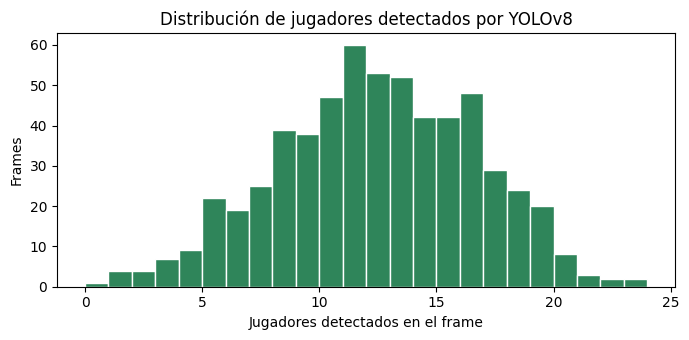


Frames comparados: 600
       player_count_yolo  player_count_blobs
count              600.0               600.0
mean                11.9                61.9
std                  4.3                21.8
min                  0.0                24.0
25%                  9.0                46.0
50%                 12.0                60.0
75%                 15.0                75.0
max                 23.0               155.0
Correlación YOLO vs blobs: -0.04


In [2]:
print(det.player_count.describe().round(2))
print('Frames sin jugadores detectados:', int((det.player_count == 0).sum()))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(det.player_count, bins=range(0, det.player_count.max()+2), color='#2f855a', edgecolor='white')
ax.set(xlabel='Jugadores detectados en el frame', ylabel='Frames',
       title='Distribución de jugadores detectados por YOLOv8')
fig.tight_layout(); fig.savefig('../outputs/12_players_per_frame.png'); plt.show()

# Comparación con el proxy por blobs de extract_features.py en los mismos frames
feat = pd.read_csv('../data/frame_features.csv')
cmp = det.merge(feat[['file', 'frame_pos', 'player_count']], on=['file', 'frame_pos'],
                suffixes=('_yolo', '_blobs'))
print('\nFrames comparados:', len(cmp))
print(cmp[['player_count_yolo', 'player_count_blobs']].describe().round(1))
print('Correlación YOLO vs blobs:', round(cmp.player_count_yolo.corr(cmp.player_count_blobs), 2))

YOLO detecta **11.9 jugadores por frame** en promedio (mediana 12, máximo 23), coherente
con los jugadores visibles en el plano táctico. En los mismos frames, el proxy por blobs
reporta alrededor de 62 y su correlación con YOLO es prácticamente **nula**: el método
de blobs cuenta ruido de gradas y líneas, no jugadores. **Decisión:** para el conteo de
jugadores se usa YOLO y se descarta el proxy por blobs.

## 2. Ejemplo de detección

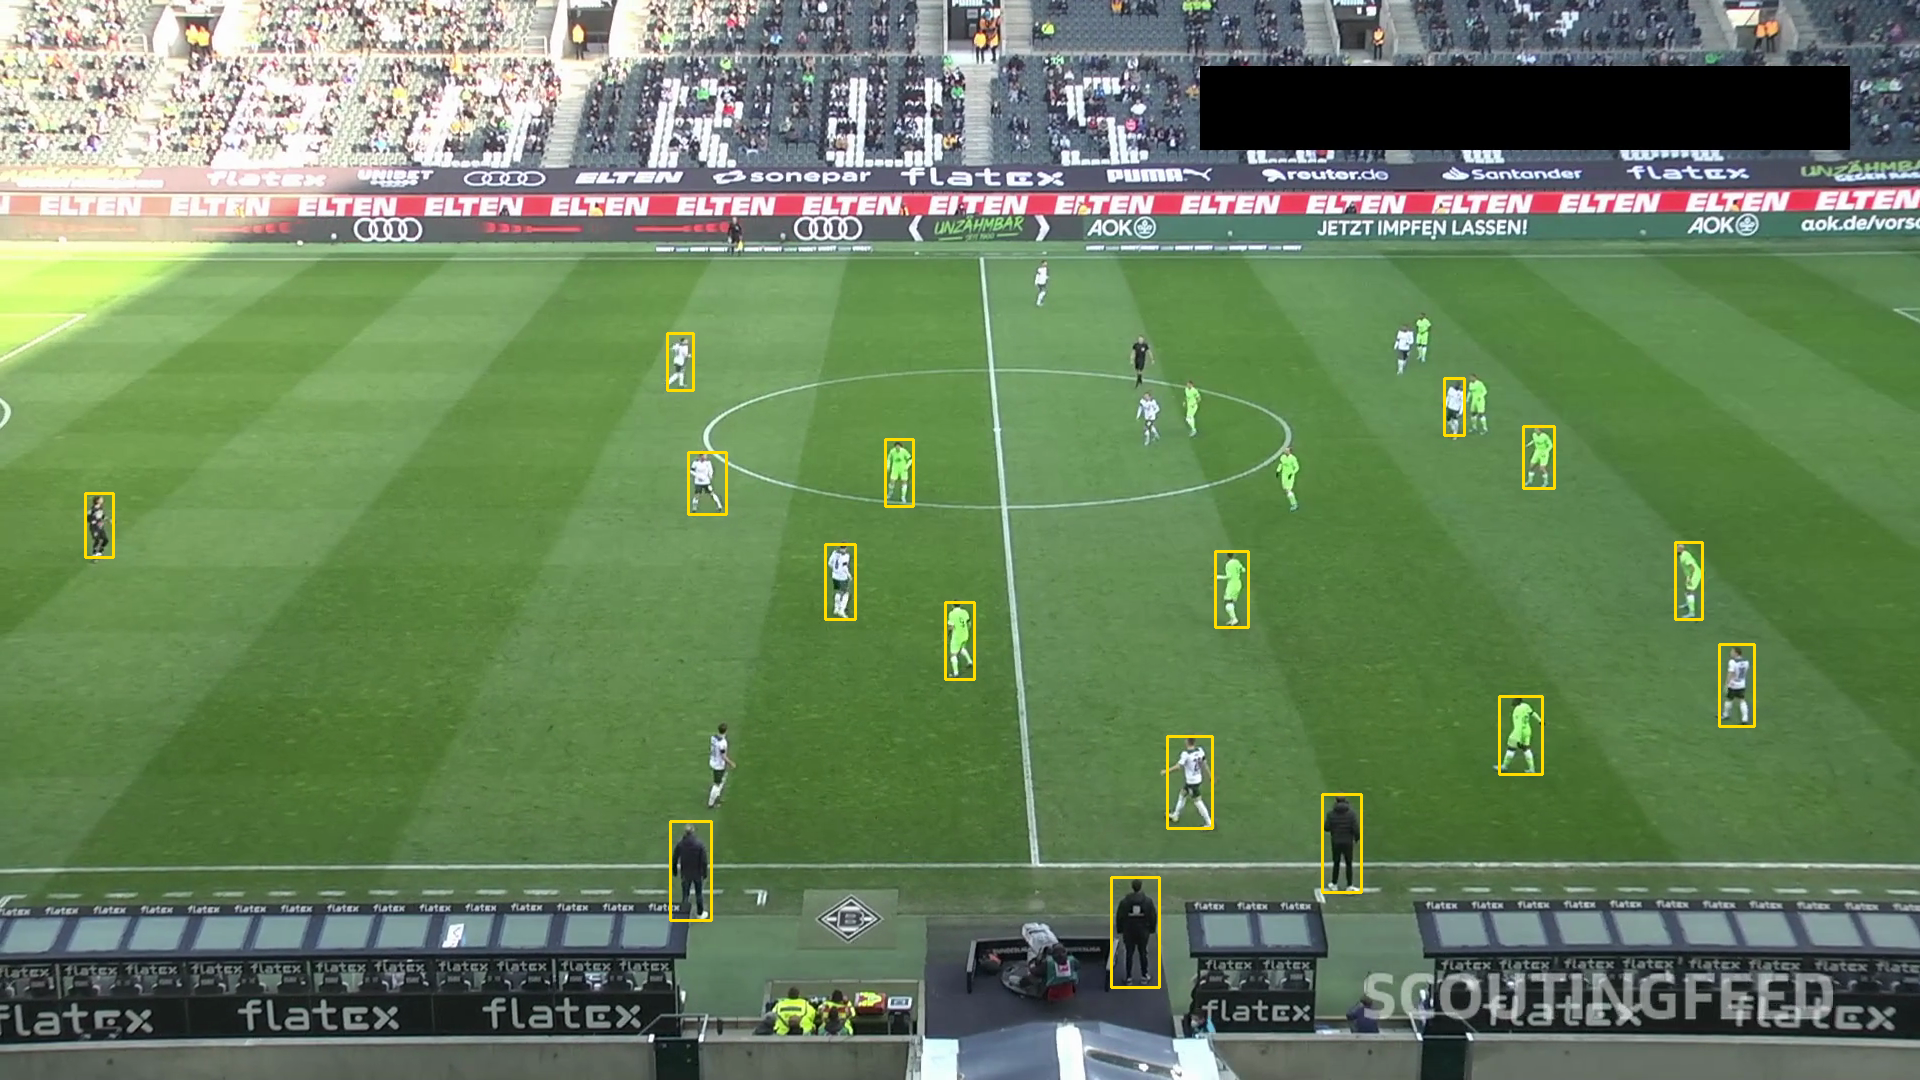

In [3]:
display(Image('../outputs/06_player_detection_example.png'))

## 3. Separación de equipos por color de camiseta

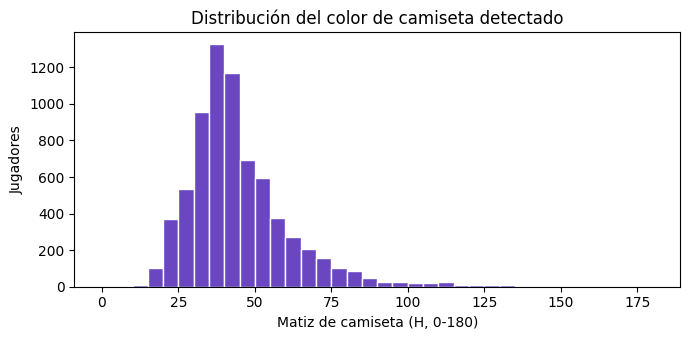

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(jer.hue, bins=36, range=(0,180), color='#6b46c1', edgecolor='white')
ax.set(xlabel='Matiz de camiseta (H, 0-180)', ylabel='Jugadores',
       title='Distribución del color de camiseta detectado')
fig.tight_layout(); fig.savefig('../outputs/13_jersey_hue_hist.png'); plt.show()

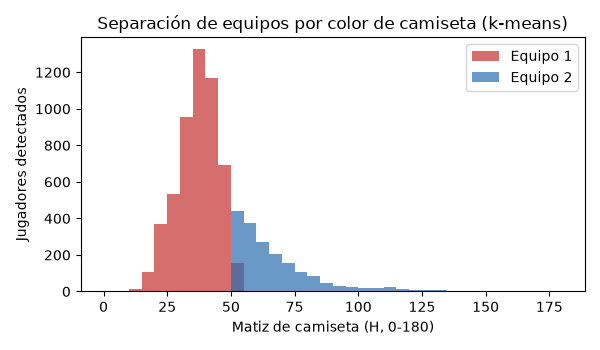

In [5]:
display(Image('../outputs/07_jersey_hue_clusters.png'))

**Separación por partido.** Al juntar los 20 partidos, el matiz forma una distribución
casi **unimodal** (entre amarillo y verde, H≈40): cada partido tiene uniformes distintos y
el recorte del torso incluye algo de césped. Por eso la separación en equipos debe
hacerse **dentro de cada partido**. Se mide con k-means (k = 2) sobre matiz circular,
saturación y valor, y con el coeficiente *silhouette* (−1 a 1; > 0.5 indica grupos
claros, 0.25–0.5 grupos moderados).

count    20.00
mean      0.41
std       0.08
min       0.28
25%       0.35
50%       0.41
75%       0.46
max       0.53
Name: silhouette, dtype: float64


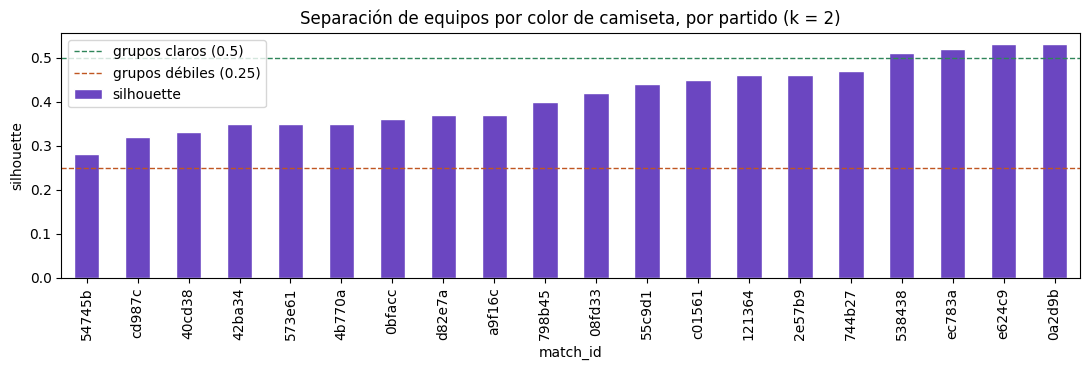

,jugadores,silhouette,equipo_menor (%)
match_id,,,
54745b,428,0.28,45.79
cd987c,303,0.32,43.56
40cd38,426,0.33,47.89
42ba34,257,0.35,33.46
573e61,367,0.35,42.78
4b770a,394,0.35,29.19
0bfacc,347,0.36,43.80
d82e7a,317,0.37,38.17
a9f16c,302,0.37,42.05


In [6]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)  # avisos numéricos de BLAS en macOS
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def color_feats(d):
    h = np.deg2rad(d.hue * 2)
    return np.c_[np.cos(h) * d.sat / 255, np.sin(h) * d.sat / 255, d.val / 255]

rows = []
for m, d in jer.groupby('match_id'):
    X = color_feats(d)
    lab = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
    rows.append({'match_id': m, 'jugadores': len(d),
                 'silhouette': silhouette_score(X, lab),
                 'equipo_menor (%)': np.bincount(lab).min() / len(d) * 100})
sil = pd.DataFrame(rows).set_index('match_id').sort_values('silhouette').round(2)
print(sil.silhouette.describe().round(2))

fig, ax = plt.subplots(figsize=(11, 3.8))
sil.silhouette.plot(kind='bar', color='#6b46c1', edgecolor='white', ax=ax)
ax.axhline(0.5, color='#2f855a', ls='--', lw=1, label='grupos claros (0.5)')
ax.axhline(0.25, color='#c05621', ls='--', lw=1, label='grupos débiles (0.25)')
ax.set(ylabel='silhouette', title='Separación de equipos por color de camiseta, por partido (k = 2)')
ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig('../outputs/19_team_silhouette.png'); plt.show()
sil

**Hallazgo.** Dentro de cada partido, el color de camiseta separa dos grupos con un
*silhouette* medio de **0.41** (de 0.28 a 0.54): separación **moderada**, con grupos de
tamaño parecido (en casi todos los partidos el menor reúne entre 30 % y 50 % de los jugadores), como se
espera de dos equipos. El color es una señal útil para asignar cada jugador a su equipo,
pero no suficiente por sí sola: árbitros, porteros y el césped dentro del recorte
introducen ruido. Conviene **segmentar la camiseta** (quitar píxeles de césped) y
combinar el color con la posición o el *tracking*.

## 4. Jugadores por partido

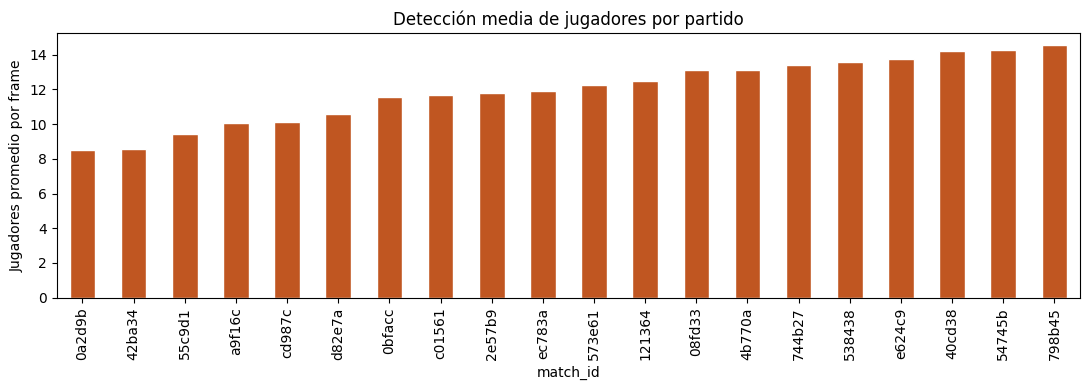

In [7]:
by_match = det.groupby('match_id').player_count.mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 4))
by_match.plot(kind='bar', color='#c05621', ax=ax, edgecolor='white')
ax.set(ylabel='Jugadores promedio por frame', title='Detección media de jugadores por partido')
fig.tight_layout(); fig.savefig('../outputs/14_players_by_match.png'); plt.show()

La detección media va de **8.5 a 14.5 jugadores por frame** según el partido: las
diferencias se atribuyen al encuadre (más o menos zoom) y a la iluminación de cada
transmisión.